# Linear public goods game with LLM players

Four LLMs (Claude, OpenAI, Grok, Gemini) play a standard repeated linear public goods game for 5 periods.
Each period every player gets an endowment $E$ and simultaneously chooses a contribution $c_i \in [0, E]$. Payoff:

$$\pi_i = E - c_i + m \sum_j c_j, \qquad 1/n < m < 1$$

With $n=4$ and $m=0.4$, contributing nothing is the dominant strategy, while full contribution maximizes the group payoff.
After each period players only learn the **sum** of all contributions (not individual ones).

Setup: copy `.env.example` to `.env` and add your API keys.

In [15]:
# %pip install -q anthropic openai python-dotenv pandas matplotlib
import json, os, re
from concurrent.futures import ThreadPoolExecutor

import anthropic
import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()

# Game parameters
N_PERIODS = 5
ENDOWMENT = 20
MPCR = 0.4  # marginal per capita return

# Model names: set to the models your accounts have access to
PLAYERS = {
    "Claude": {"provider": "anthropic", "model": "claude-opus-5-5"},
    "OpenAI": {"provider": "openai", "model": "gpt-5.5"},
    "Grok": {"provider": "xai", "model": "grok-4.7"},
    "Gemini": {"provider": "google", "model": "gemini-3.8-flash"},
}
N = len(PLAYERS)

clients = {
    "anthropic": anthropic.Anthropic(api_key=os.environ["ANTHROPIC_API_KEY"]),
    "openai": OpenAI(api_key=os.environ["OPENAI_API_KEY"]),
    "xai": OpenAI(api_key=os.environ["XAI_API_KEY"], base_url="https://api.x.ai/v1"),
    # Gemini is called through Google's OpenAI-compatible endpoint, so no extra package is needed
    "google": OpenAI(
        api_key=os.environ["GOOGLE_API_KEY"],
        base_url="https://generativelanguage.googleapis.com/v1beta/openai/",
    ),
}

In [ ]:
INSTRUCTIONS = f"""You are participating in an economic experiment with {N} players (including you) over {N_PERIODS} periods.
In each period every player receives {ENDOWMENT} tokens and simultaneously decides how many tokens (an integer from 0 to {ENDOWMENT}) to contribute to a group project.
Tokens not contributed are kept. Each token in the project returns {MPCR} tokens to EVERY player, regardless of who contributed it.
Your period payoff = {ENDOWMENT} - your contribution + {MPCR} x (sum of all players' contributions).
After each period you learn the total contributions of the group, but not individual contributions.
"""

# Treatment-specific text appended to the instructions
TREATMENTS = {
    "baseline": "",
    "llm_info": (
        f"The other {N - 1} players are also large language models (AI systems), each from a different developer. "
        "None of them is a copy of you."
    ),
}


def build_prompt(history, own_contribs, period, treatment):
    lines = [INSTRUCTIONS]
    if TREATMENTS[treatment]:
        lines.append(TREATMENTS[treatment] + "\n")
    for t, (total, own) in enumerate(zip(history, own_contribs), 1):
        payoff = ENDOWMENT - own + MPCR * total
        lines.append(f"Period {t}: you contributed {own}, group total was {total}, your payoff was {payoff:.1f}.")
    lines.append(f"\nPeriod {period} of {N_PERIODS}. How many tokens do you contribute?")
    lines.append('Answer only with JSON: {"contribution": <integer>}')
    return "\n".join(lines)


def ask(provider, model, prompt):
    if provider == "anthropic":
        r = clients[provider].messages.create(
            model=model, max_tokens=4000, messages=[{"role": "user", "content": prompt}]
        )
        return next(b.text for b in r.content if b.type == "text")
    r = clients[provider].chat.completions.create(
        model=model, messages=[{"role": "user", "content": prompt}]
    )
    return r.choices[0].message.content


def parse(text):
    m = re.search(r'"contribution"\s*:\s*(\d+)', text) or re.search(r"\d+", text)
    value = int(m.group(1) if m.lastindex else m.group(0))
    return min(max(value, 0), ENDOWMENT)


In [17]:
def run_game(treatment):
    history = []  # group totals per period (the only public information)
    own = {name: [] for name in PLAYERS}
    raw = []
    for period in range(1, N_PERIODS + 1):
        prompts = {n: build_prompt(history, own[n], period, treatment) for n in PLAYERS}
        # Simultaneous decisions: all players are queried in parallel
        with ThreadPoolExecutor(max_workers=N) as pool:
            futures = {n: pool.submit(ask, PLAYERS[n]["provider"], PLAYERS[n]["model"], prompts[n]) for n in PLAYERS}
            answers = {n: f.result() for n, f in futures.items()}
        choices = {n: parse(a) for n, a in answers.items()}
        for n in PLAYERS:
            own[n].append(choices[n])
            raw.append({"treatment": treatment, "period": period, "player": n, "answer": answers[n]})
        history.append(sum(choices.values()))
        print(f"[{treatment}] Period {period}: {choices} -> total {history[-1]}")
    df = pd.DataFrame(own, index=range(1, N_PERIODS + 1)).rename_axis("period")
    return df, raw


results, raws = {}, []
for treatment in TREATMENTS:
    results[treatment], raw = run_game(treatment)
    raws += raw

pd.concat(results, names=["treatment"]).to_csv("results.csv")
pd.DataFrame(raws).to_csv("raw_answers.csv", index=False)


[baseline] Period 1: {'Claude': 20, 'OpenAI': 0, 'Grok': 0, 'Gemini': 20} -> total 40
[baseline] Period 2: {'Claude': 10, 'OpenAI': 0, 'Grok': 0, 'Gemini': 7} -> total 17
[baseline] Period 3: {'Claude': 5, 'OpenAI': 0, 'Grok': 0, 'Gemini': 3} -> total 8
[baseline] Period 4: {'Claude': 0, 'OpenAI': 0, 'Grok': 0, 'Gemini': 0} -> total 0
[baseline] Period 5: {'Claude': 0, 'OpenAI': 0, 'Grok': 0, 'Gemini': 0} -> total 0
[llm_info] Period 1: {'Claude': 20, 'OpenAI': 20, 'Grok': 0, 'Gemini': 20} -> total 60
[llm_info] Period 2: {'Claude': 20, 'OpenAI': 15, 'Grok': 0, 'Gemini': 15} -> total 50
[llm_info] Period 3: {'Claude': 15, 'OpenAI': 10, 'Grok': 0, 'Gemini': 10} -> total 35
[llm_info] Period 4: {'Claude': 8, 'OpenAI': 5, 'Grok': 0, 'Gemini': 5} -> total 18
[llm_info] Period 5: {'Claude': 0, 'OpenAI': 0, 'Grok': 0, 'Gemini': 0} -> total 0


Total payoffs [baseline]: Claude 91.0, OpenAI 126.0, Grok 126.0, Gemini 96.0
Total payoffs [llm_info]: Claude 102.2, OpenAI 115.2, Grok 165.2, Gemini 115.2


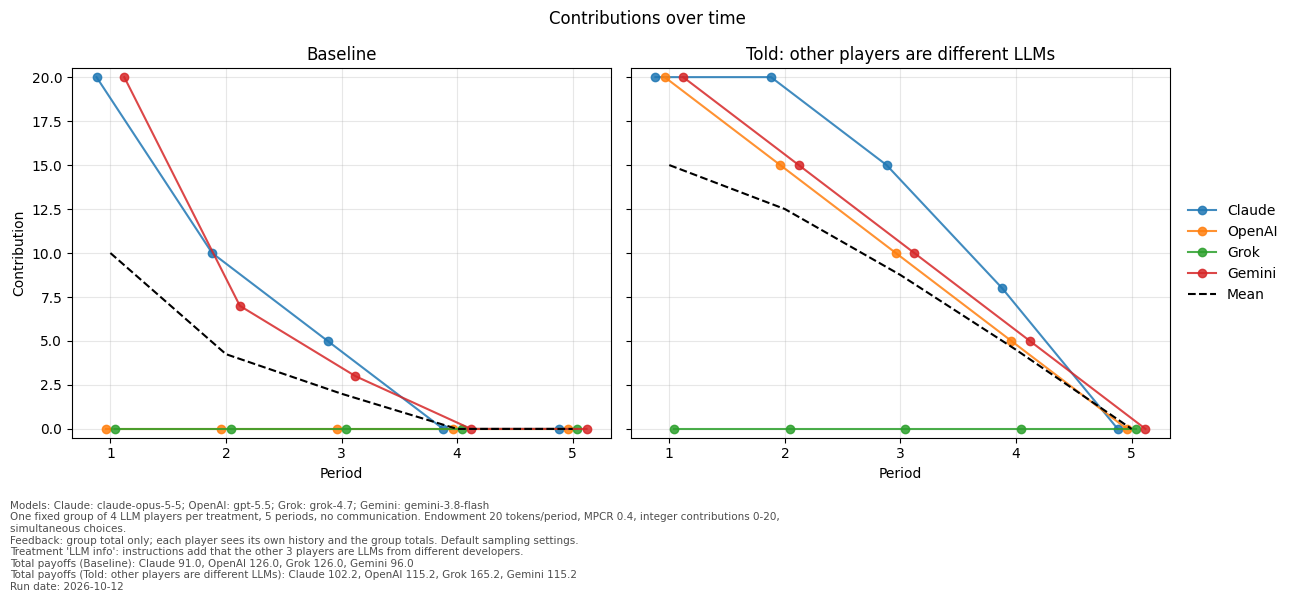

In [18]:
import textwrap

import numpy as np

TITLES = {"baseline": "Baseline", "llm_info": "Told: other players are different LLMs"}

payoffs = {t: ENDOWMENT - d + MPCR * d.sum(axis=1).values[:, None] for t, d in results.items()}
total_pay = {t: ", ".join(f"{n} {v:.1f}" for n, v in p.sum().items()) for t, p in payoffs.items()}
for t, s in total_pay.items():
    print(f"Total payoffs [{t}]: {s}")

models = "; ".join(f"{n}: {p['model']}" for n, p in PLAYERS.items())
paras = [
    f"Models: {models}",
    f"One fixed group of {N} LLM players per treatment, {N_PERIODS} periods, no communication. "
    f"Endowment {ENDOWMENT} tokens/period, MPCR {MPCR}, integer contributions 0-{ENDOWMENT}, simultaneous choices.",
    "Feedback: group total only; each player sees its own history and the group totals. Default sampling settings.",
    f"Treatment 'LLM info': instructions add that the other {N - 1} players are LLMs from different developers.",
    *(f"Total payoffs ({TITLES[t]}): {s}" for t, s in total_pay.items()),
    f"Run date: {pd.Timestamp.now():%Y-%m-%d}",
]
note = "\n".join(textwrap.fill(p, 150) for p in paras)

fig, axes = plt.subplots(1, len(results), figsize=(13, 6), sharey=True)
offsets = np.linspace(-0.12, 0.12, N)  # fixed offsets so identical choices stay visible
for ax, (t, d) in zip(axes, results.items()):
    for off, col in zip(offsets, d.columns):
        ax.plot(d.index + off, d[col], marker="o", alpha=0.85, label=col)
    ax.plot(d.index, d.mean(axis=1), color="k", ls="--", label="Mean")
    ax.set(xlabel="Period", ylim=(-0.5, ENDOWMENT + 0.5), title=TITLES[t])
    ax.set_xticks(d.index)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Contribution")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
fig.suptitle("Contributions over time")
fig.text(0.01, 0.01, note, ha="left", va="bottom", fontsize=7.5, color="0.3")
fig.tight_layout(rect=(0, 0.17, 1, 1))
plt.savefig("contributions.png", dpi=150)
plt.show()
